# 10 · Williams–Otto SOSX input-noise stress test

This notebook tests whether the globally trained SOSX PWL-tanh surrogate remains
stable when its **training inputs contain small measurement errors**.

The core stress test compares two otherwise identical SOSX pipelines:

1. **Clean-input SOSX** — trained with the exact sampled `(FB, TR)` values.
2. **Noisy-input SOSX** — trained with Gaussian perturbations added only to the
   training inputs. The labels remain the simulator outputs at the original clean
   points, representing errors-in-variables or sensor noise.

To make the robustness claim interpretable, the notebook also adds clean-data
smooth/PWL/physics-informed baselines, constrained-vs-unconstrained optimization,
noise-level sweeps, pruning sensitivity, and opt-in repeated-seed / drift checks.

Validation and test inputs remain clean and are never used by the optimizer.
The notebook also evaluates both networks under repeated noisy test inputs.

This experiment can provide evidence against overfitting, but one noise level and
one random seed cannot prove robustness. For release evidence, repeat the notebook
over several seeds and noise levels and summarize confidence intervals.

In [1]:
from __future__ import annotations

import os
import sys
import time
from pathlib import Path

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("TF_NUM_INTRAOP_THREADS", "1")
os.environ.setdefault("TF_NUM_INTEROP_THREADS", "1")
os.environ.setdefault("MPLCONFIGDIR", "/tmp/pwlnet-matplotlib")


def find_project_root(start: Path) -> Path:
    for candidate in (start, *start.parents):
        if (candidate / "src" / "pwlnet").exists() and (candidate / "pyproject.toml").exists():
            return candidate
    raise RuntimeError("Could not find the PWLNet project root.")


ROOT = find_project_root(Path.cwd().resolve())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pwlnet import PWLNet, regression_metrics, solve_sosx, train_val_test_split
from pwlnet.core.network import NetworkDefinition
from pwlnet.formulations.pyomo_pwl import evaluate_tanh_pwl_network
from pwlnet.processes.williams_otto import (
    EXACT_OPTIMUM,
    INPUT_NAMES,
    OUTPUT_NAMES,
    WilliamsOttoParameters,
    generate_dataset,
    solve_surrogate_optimization_model,
)
from pwlnet.solvers import find_ipopt

plt.style.use("seaborn-v0_8-whitegrid")
params = WilliamsOttoParameters()

## 1 · Experiment configuration

Noise is defined as a fraction of each physical input range:

\[
\tilde{x}_{ij} = x_{ij} + \epsilon_{ij},
\qquad
\epsilon_{ij} \sim \mathcal{N}(0, (\alpha R_j)^2).
\]

The perturbed values are clipped to the Williams–Otto operating box. The default
`NOISE_FRACTION=0.01` means a standard deviation of 1% of the `FB` and `TR`
ranges.

In [2]:
FAST_MODE = False
RANDOM_SEED = 19
NOISE_SEED = 2026
N_SAMPLES = 40 if FAST_MODE else 120
HIDDEN = 3 if FAST_MODE else 6
PWL_BREAKPOINTS = 5
PWL_FB_SEGMENTS = 10
NOISE_FRACTION = 0.05
NOISE_FRACTION_SWEEP = [0.0, 0.01, 0.03, 0.05]
NOISY_TEST_REPEATS = 50 if FAST_MODE else 200
REPEATED_SEEDS = [19, 23, 29]
RUN_EXTENDED_ROBUSTNESS = False
RUN_APPENDIX_PLOTS = False

SOLVER = "appsi_highs"
SOSX_MAX_NODES = 1500 if FAST_MODE else 15000
SOSX_TIME_LIMIT = 120.0 if FAST_MODE else 1500.0
SOSX_RELATIVE_GAP = 1e-3
SOSX_PARALLEL = False
SOSX_WORKERS = None

KERAS_OPTIONS = {
    "epochs": 300 if FAST_MODE else 800,
    "batch_size": 16,
    "early_stopping_patience": 40,
    "verbose": 0,
}

input_lower = np.array([params.fb_bounds[0], params.tr_bounds[0]], dtype=float)
input_upper = np.array([params.fb_bounds[1], params.tr_bounds[1]], dtype=float)
input_range = input_upper - input_lower
noise_std = NOISE_FRACTION * input_range

print(
    f"samples={N_SAMPLES}, hidden={HIDDEN}, breakpoints={PWL_BREAKPOINTS}, "
    f"noise={100 * NOISE_FRACTION:.2f}% of input range"
)
print(dict(zip(INPUT_NAMES, noise_std)))

samples=120, hidden=6, breakpoints=5, noise=5.00% of input range
{'FB': np.float64(0.15000000000000002), 'TR': np.float64(1.5)}


## 2 · Shared data split and noisy training inputs

In [3]:
data = generate_dataset(
    n_samples=N_SAMPLES,
    method="lhs",
    random_state=RANDOM_SEED,
    as_frame=True,
)
split = train_val_test_split(
    data,
    val_size=0.2,
    test_size=0.2,
    random_state=RANDOM_SEED,
)
train_df, val_df, test_df = split.train, split.validation, split.test


def split_xy(frame):
    return (
        frame[INPUT_NAMES].to_numpy(dtype=float),
        frame[OUTPUT_NAMES].to_numpy(dtype=float),
    )


X_train, y_train = split_xy(train_df)
X_val, y_val = split_xy(val_df)
X_test, y_test = split_xy(test_df)

rng = np.random.default_rng(NOISE_SEED)
training_noise = rng.normal(0.0, noise_std, size=X_train.shape)
X_train_noisy = np.clip(X_train + training_noise, input_lower, input_upper)

noise_summary = pd.DataFrame(
    {
        "input": INPUT_NAMES,
        "configured std": noise_std,
        "realized mean error": training_noise.mean(axis=0),
        "realized RMSE": np.sqrt(np.mean((X_train_noisy - X_train) ** 2, axis=0)),
        "max abs error": np.max(np.abs(X_train_noisy - X_train), axis=0),
    }
)
display(noise_summary)
print(
    f"data: {len(data)} -> train {len(train_df)} / "
    f"validation {len(val_df)} / test {len(test_df)}"
)

,input,configured std,realized mean error,realized RMSE,max abs error
0,FB,0.15,-0.005285,0.147194,0.383919
1,TR,1.50,0.199063,1.579685,4.726362


data: 120 -> train 72 / validation 24 / test 24


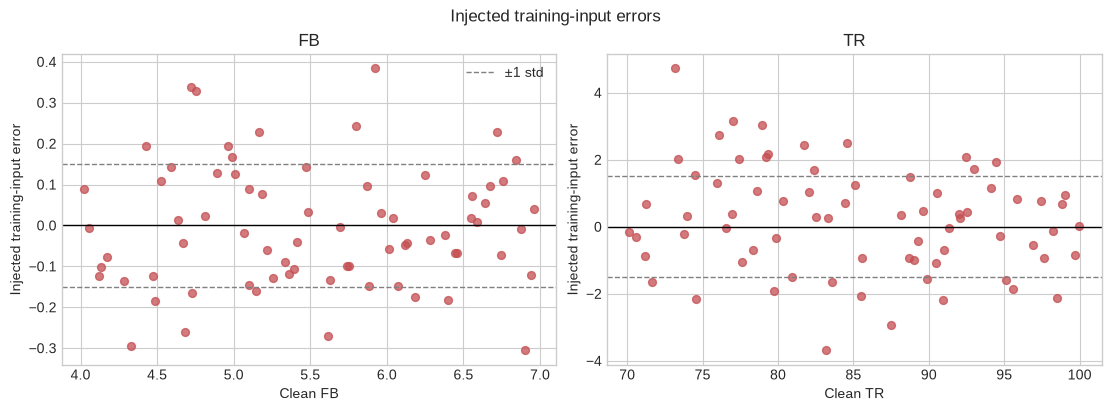

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
for j, (ax, name) in enumerate(zip(axes, INPUT_NAMES)):
    ax.scatter(
        X_train[:, j],
        X_train_noisy[:, j] - X_train[:, j],
        s=32,
        alpha=0.75,
        color="#C44E52",
    )
    ax.axhline(0.0, color="black", linewidth=1)
    ax.axhline(noise_std[j], color="gray", linestyle="--", linewidth=1, label="±1 std")
    ax.axhline(-noise_std[j], color="gray", linestyle="--", linewidth=1)
    ax.set_xlabel(f"Clean {name}")
    ax.set_ylabel("Injected training-input error")
    ax.set_title(name)
axes[0].legend(frameon=False)
fig.suptitle("Injected training-input errors")
plt.show()

## 3 · Train clean and noisy SOSX models

Both runs use the same architecture, seed, breakpoint set, bounds policy, solver,
search settings, and Keras pretraining options. Each pipeline performs its own
Keras readout pretrain because the clean and noisy input scalers differ. This
keeps each fixed `W2` and warm-start network internally consistent.

In [5]:
COMMON_SOSX = dict(
    hidden_neurons=HIDDEN,
    breakpoints=PWL_BREAKPOINTS,
    readout="keras",
    solver=SOLVER,
    solver_options={"persistent": True},
    max_nodes=SOSX_MAX_NODES,
    time_limit=SOSX_TIME_LIMIT,
    relative_gap=SOSX_RELATIVE_GAP,
    random_seed=RANDOM_SEED,
    keras_options=KERAS_OPTIONS,
    parallel=SOSX_PARALLEL,
    n_workers=SOSX_WORKERS,
    verbose=False,
)


def fit_sosx(label, X_fit):
    start = time.perf_counter()
    model = PWLNet.train_sosx(
        X_fit,
        y_train,
        validation_data=(X_val, y_val),
        **COMMON_SOSX,
    )
    seconds = time.perf_counter() - start
    result = model.trainer.result_
    print(
        f"{label}: {seconds:.3f} s, status={result.status}, "
        f"nodes={result.n_nodes}, objective={result.objective}, "
        f"relative_gap={result.relative_gap}"
    )
    return model, seconds


clean_model, clean_training_seconds = fit_sosx("clean-input SOSX", X_train)
noisy_model, noisy_training_seconds = fit_sosx("noisy-input SOSX", X_train_noisy)

I0000 00:00:1782511812.458716  718137 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1782511813.437006  718137 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
E0000 00:00:1782511813.574937  718137 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


clean-input SOSX: 30.644 s, status=optimal, nodes=2, objective=0.06983944985104769, relative_gap=0.0
noisy-input SOSX: 28.989 s, status=optimal, nodes=2, objective=0.16717920328702165, relative_gap=0.0


### Clean-data smooth, PWL, and physics-informed baselines

These baselines are trained both on the clean split and on the same noisy-input split so the SOSX noise experiment
has context. `PWL tanh` reuses the smooth weights and only changes the deployment
activation approximation; `PI-PWL tanh` uses physics-informed training followed by
the same PWL deployment path.

In [6]:
COMMON_KERAS = dict(
    hidden_layers=[HIDDEN],
    activation="tanh",
    validation_data=(X_val, y_val),
    random_seed=RANDOM_SEED,
    **KERAS_OPTIONS,
)

t0 = time.perf_counter()
smooth_model = PWLNet.train(X_train, y_train, loss="mse", **COMMON_KERAS)
smooth_training_seconds = time.perf_counter() - t0

t0 = time.perf_counter()
noisy_smooth_model = PWLNet.train(X_train_noisy, y_train, loss="mse", **COMMON_KERAS)
noisy_smooth_training_seconds = time.perf_counter() - t0

PI_WEIGHTS = {"closure": 1.0, "bounds": 1.0}
t0 = time.perf_counter()
pi_model = PWLNet.train_physics_informed(
    X_train,
    y_train,
    physics="williams_otto",
    physics_weights=PI_WEIGHTS,
    **COMMON_KERAS,
)
pi_training_seconds = time.perf_counter() - t0

t0 = time.perf_counter()
noisy_pi_model = PWLNet.train_physics_informed(
    X_train_noisy,
    y_train,
    physics="williams_otto",
    physics_weights=PI_WEIGHTS,
    **COMMON_KERAS,
)
noisy_pi_training_seconds = time.perf_counter() - t0

print(f"smooth tanh: {smooth_training_seconds:.3f} s")
print(f"noisy-input smooth tanh: {noisy_smooth_training_seconds:.3f} s")
print(f"PI tanh: {pi_training_seconds:.3f} s")
print(f"noisy-input PI tanh: {noisy_pi_training_seconds:.3f} s")
print(smooth_model.summary())
print(pi_model.summary())


smooth tanh: 31.850 s
noisy-input smooth tanh: 31.985 s
PI tanh: 5.855 s
noisy-input PI tanh: 5.711 s
NetworkDefinition: 2 inputs -> 6 outputs, 2 layers, 6 hidden neurons, 60 parameters
layer   n_in  n_out activation   params
    0      2      6       tanh       18
    1      6      6     linear       42
NetworkDefinition: 2 inputs -> 6 outputs, 2 layers, 6 hidden neurons, 60 parameters
layer   n_in  n_out activation   params
    0      2      6       tanh       18
    1      6      6     linear       42


In [7]:
def pin_operating_bounds(model: PWLNet) -> None:
    network = model.network
    model.network = NetworkDefinition(
        layers=network.layers,
        input_scaler=network.input_scaler,
        output_scaler=network.output_scaler,
        input_bounds=[
            tuple(map(float, params.fb_bounds)),
            tuple(map(float, params.tr_bounds)),
        ],
    )


for model in (smooth_model, noisy_smooth_model, pi_model, noisy_pi_model, clean_model, noisy_model):
    pin_operating_bounds(model)


def predict_pwl(model, X):
    return evaluate_tanh_pwl_network(
        model.network,
        X,
        breakpoints=PWL_BREAKPOINTS,
    )

## 4 · Prediction metrics and generalization gap

`train observed` evaluates each model on the input values it actually saw during
training. `train clean` evaluates both models at the true clean training points.
Validation and test metrics are always computed on untouched clean data.

The train-to-test MAE gap is included as a simple overfitting indicator. A small
gap is useful evidence, but it should be interpreted together with absolute test
error and repeated-seed results.

In [8]:
model_colors = {
    "Smooth tanh": "#4C72B0",
    "PWL tanh": "#55A868",
    "Noisy smooth tanh": "#64B5CD",
    "Noisy PWL tanh": "#8CCB8C",
    "PI-PWL tanh": "#C44E52",
    "Noisy PI-PWL tanh": "#E17C7C",
    "Clean-input SOSX": "#8172B2",
    "Noisy-input SOSX": "#DD8452",
}

model_markers = {
    "Smooth tanh": "o",
    "PWL tanh": "s",
    "Noisy smooth tanh": "^",
    "Noisy PWL tanh": "v",
    "PI-PWL tanh": "P",
    "Noisy PI-PWL tanh": "H",
    "Clean-input SOSX": "X",
    "Noisy-input SOSX": "D",
}

models = {
    "Smooth tanh": smooth_model,
    "PWL tanh": smooth_model,
    "Noisy smooth tanh": noisy_smooth_model,
    "Noisy PWL tanh": noisy_smooth_model,
    "PI-PWL tanh": pi_model,
    "Noisy PI-PWL tanh": noisy_pi_model,
    "Clean-input SOSX": clean_model,
    "Noisy-input SOSX": noisy_model,
}

predictors = {
    "Smooth tanh": lambda X: smooth_model.predict(X),
    "PWL tanh": lambda X: predict_pwl(smooth_model, X),
    "Noisy smooth tanh": lambda X: noisy_smooth_model.predict(X),
    "Noisy PWL tanh": lambda X: predict_pwl(noisy_smooth_model, X),
    "PI-PWL tanh": lambda X: predict_pwl(pi_model, X),
    "Noisy PI-PWL tanh": lambda X: predict_pwl(noisy_pi_model, X),
    "Clean-input SOSX": lambda X: predict_pwl(clean_model, X),
    "Noisy-input SOSX": lambda X: predict_pwl(noisy_model, X),
}

observed_training_inputs = {
    "Smooth tanh": X_train,
    "PWL tanh": X_train,
    "Noisy smooth tanh": X_train_noisy,
    "Noisy PWL tanh": X_train_noisy,
    "PI-PWL tanh": X_train,
    "Noisy PI-PWL tanh": X_train_noisy,
    "Clean-input SOSX": X_train,
    "Noisy-input SOSX": X_train_noisy,
}

MODEL_FAMILIES = {
    "Smooth tanh": ("Smooth tanh", "Noisy smooth tanh"),
    "PWL tanh": ("PWL tanh", "Noisy PWL tanh"),
    "PI-PWL tanh": ("PI-PWL tanh", "Noisy PI-PWL tanh"),
    "SOSX": ("Clean-input SOSX", "Noisy-input SOSX"),
}
MAIN_PARITY_MODELS = ["PWL tanh", "Noisy PWL tanh", "Clean-input SOSX", "Noisy-input SOSX"]
MAIN_LANDSCAPE_MODELS = MAIN_PARITY_MODELS
APPENDIX_MODELS = list(models)

family_colors = {
    "Smooth tanh": "#4C72B0",
    "PWL tanh": "#55A868",
    "PI-PWL tanh": "#C44E52",
    "SOSX": "#8172B2",
}

prediction_sets = {}
metric_rows = []
for label, predict in predictors.items():
    prediction_sets[label] = {
        "train observed": predict(observed_training_inputs[label]),
        "train clean": predict(X_train),
        "validation clean": predict(X_val),
        "test clean": predict(X_test),
    }
    truth_sets = {
        "train observed": y_train,
        "train clean": y_train,
        "validation clean": y_val,
        "test clean": y_test,
    }
    for split_name, prediction in prediction_sets[label].items():
        metric_rows.append(
            {
                "model": label,
                "split": split_name,
                **regression_metrics(truth_sets[split_name], prediction),
            }
        )

metrics = pd.DataFrame(metric_rows)
display(metrics)

generalization = (
    metrics.pivot(index="model", columns="split", values="MAE")
    .assign(
        train_to_test_gap=lambda table: table["test clean"] - table["train observed"],
        clean_train_to_test_gap=lambda table: table["test clean"] - table["train clean"],
    )
)
display(generalization)

paired_generalization_rows = []
for family, (clean_label, noisy_label) in MODEL_FAMILIES.items():
    clean_mae = float(generalization.loc[clean_label, "test clean"])
    noisy_mae = float(generalization.loc[noisy_label, "test clean"])
    paired_generalization_rows.append(
        {
            "family": family,
            "clean model": clean_label,
            "noisy model": noisy_label,
            "clean test MAE": clean_mae,
            "noisy test MAE": noisy_mae,
            "noisy - clean MAE": noisy_mae - clean_mae,
            "relative change [%]": 100.0 * (noisy_mae - clean_mae) / max(clean_mae, 1e-12),
        }
    )
paired_generalization = pd.DataFrame(paired_generalization_rows)
display(paired_generalization)


,model,split,MAE,MSE,RMSE,R2,n_samples
0,Smooth tanh,train observed,0.001542,0.000006,0.002489,0.995189,72
1,Smooth tanh,train clean,0.001542,0.000006,0.002489,0.995189,72
2,Smooth tanh,validation clean,0.001523,0.000005,0.002192,0.996387,24
3,Smooth tanh,test clean,0.001677,0.000008,0.002802,0.995392,24
4,PWL tanh,train observed,0.002259,0.000014,0.003796,0.988812,72
5,PWL tanh,train clean,0.002259,0.000014,0.003796,0.988812,72
6,PWL tanh,validation clean,0.002065,0.000010,0.003153,0.992526,24
7,PWL tanh,test clean,0.002623,0.000019,0.004384,0.988713,24
8,Noisy smooth tanh,train observed,0.004132,0.000039,0.006250,0.969673,72
9,Noisy smooth tanh,train clean,0.002598,0.000019,0.004356,0.985264,72


split,test clean,train clean,train observed,validation clean,train_to_test_gap,clean_train_to_test_gap
model,,,,,,
Clean-input SOSX,0.001968,0.001685,0.001685,0.001775,0.000283,0.000283
Noisy PI-PWL tanh,0.003910,0.003360,0.005119,0.002844,-0.001209,0.000550
Noisy PWL tanh,0.003482,0.002817,0.004547,0.002687,-0.001064,0.000665
Noisy smooth tanh,0.002690,0.002598,0.004132,0.002774,-0.001441,0.000092
Noisy-input SOSX,0.003942,0.002974,0.004449,0.002814,-0.000507,0.000968
PI-PWL tanh,0.002907,0.002468,0.002468,0.002197,0.000439,0.000439
PWL tanh,0.002623,0.002259,0.002259,0.002065,0.000364,0.000364
Smooth tanh,0.001677,0.001542,0.001542,0.001523,0.000135,0.000135


,family,clean model,noisy model,clean test MAE,noisy test MAE,noisy - clean MAE,relative change [%]
0,Smooth tanh,Smooth tanh,Noisy smooth tanh,0.001677,0.002690,0.001014,60.460550
1,PWL tanh,PWL tanh,Noisy PWL tanh,0.002623,0.003482,0.000859,32.749782
2,PI-PWL tanh,PI-PWL tanh,Noisy PI-PWL tanh,0.002907,0.003910,0.001003,34.521022
3,SOSX,Clean-input SOSX,Noisy-input SOSX,0.001968,0.003942,0.001974,100.279310


## 5 · Main clean-test parity plots

The full eight-model parity set is too dense for the main narrative. The main
figures keep the two deployment-relevant comparisons: PWL clean/noisy and SOSX
clean/noisy. Full numeric metrics for all models remain in the tables, and the
all-model plots are moved to the appendix section.


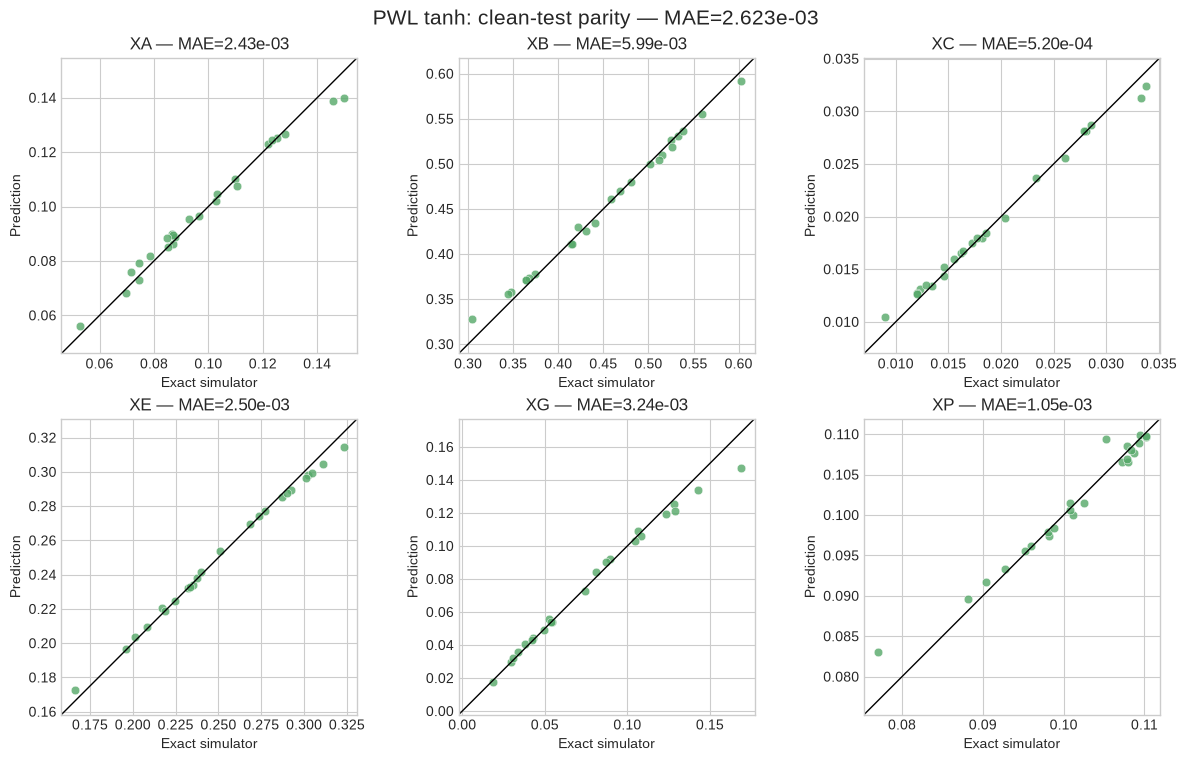

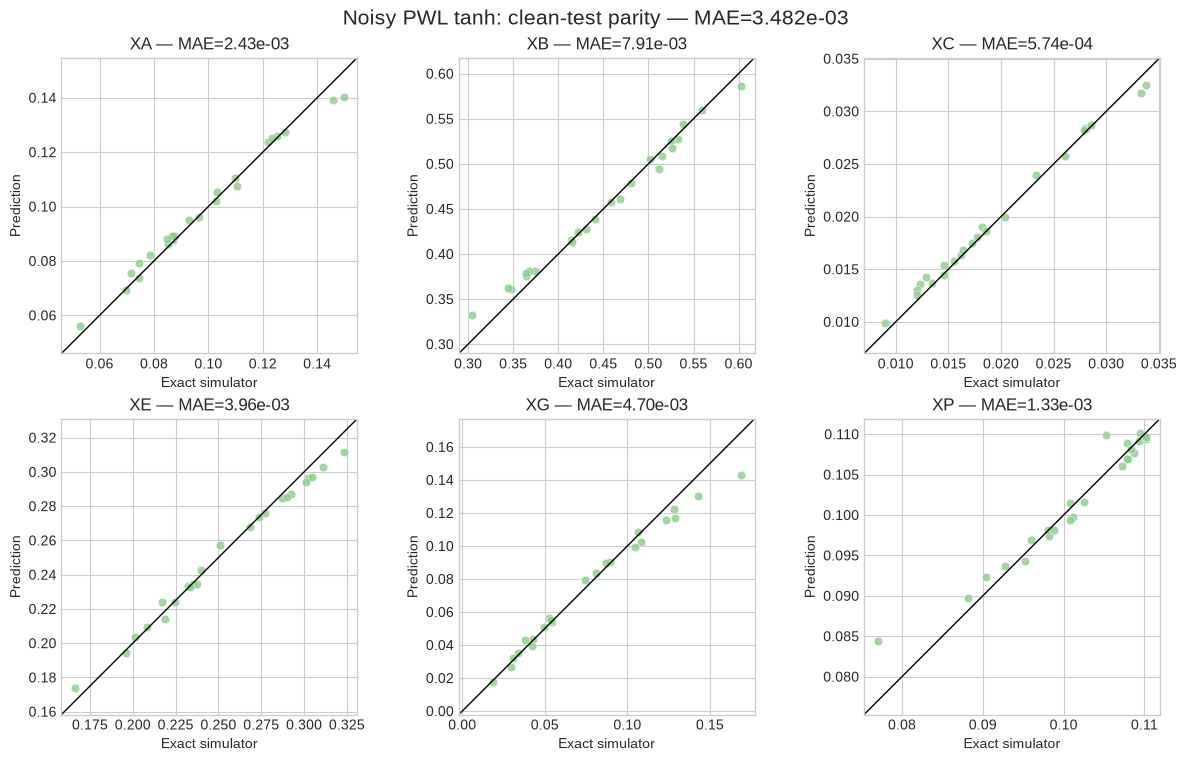

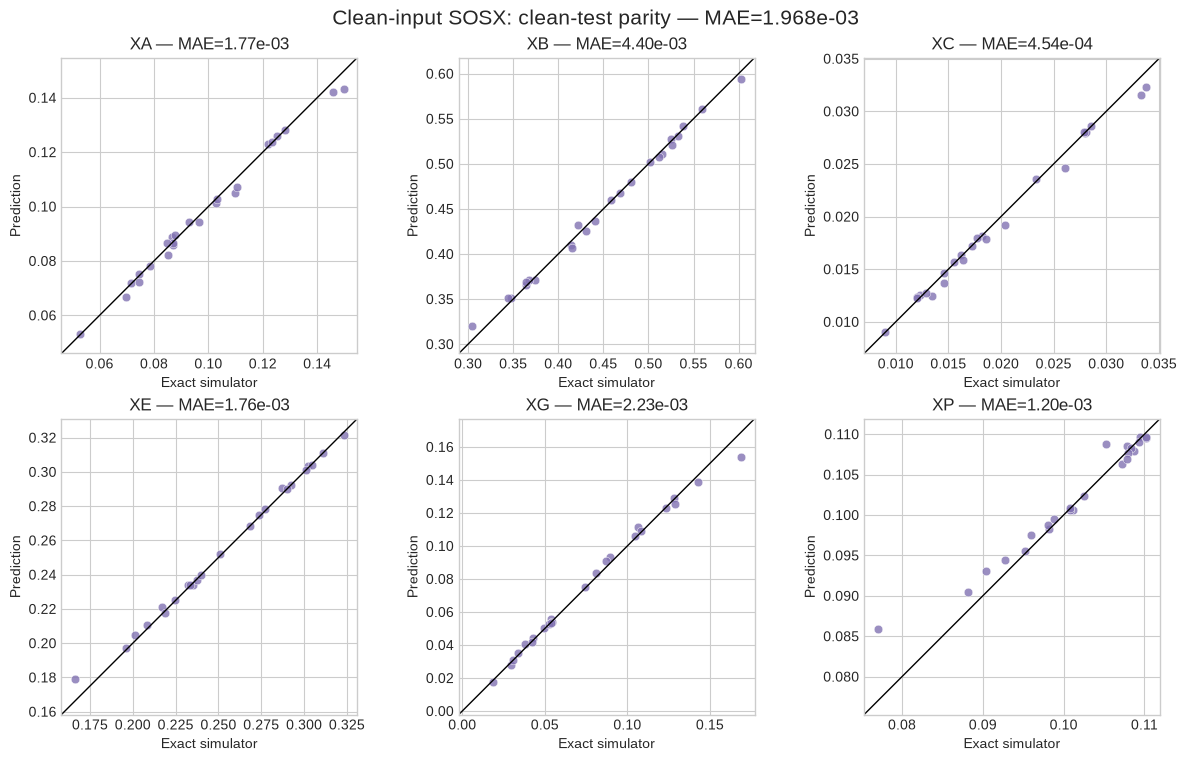

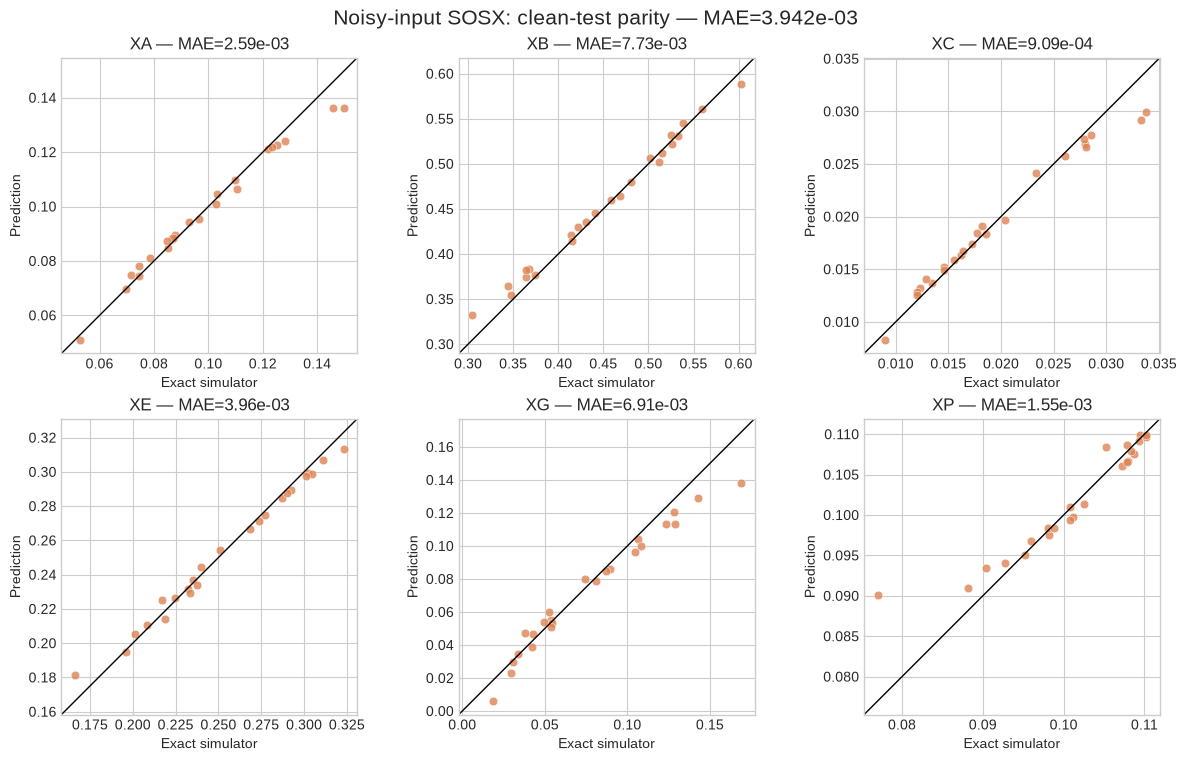

In [9]:
test_predictions = {
    label: prediction_sets[label]["test clean"]
    for label in MAIN_PARITY_MODELS
}

output_limits = []
for j in range(len(OUTPUT_NAMES)):
    values = [y_test[:, j]] + [pred[:, j] for pred in test_predictions.values()]
    lo = float(min(value.min() for value in values))
    hi = float(max(value.max() for value in values))
    pad = 0.05 * max(hi - lo, 1e-8)
    output_limits.append((lo - pad, hi + pad))

for label, prediction in test_predictions.items():
    fig, axes = plt.subplots(2, 3, figsize=(12, 7.5), constrained_layout=True)
    for j, (ax, output) in enumerate(zip(axes.ravel(), OUTPUT_NAMES)):
        lo, hi = output_limits[j]
        output_mae = float(np.mean(np.abs(prediction[:, j] - y_test[:, j])))
        ax.scatter(
            y_test[:, j],
            prediction[:, j],
            s=38,
            alpha=0.8,
            color=model_colors[label],
            edgecolor="white",
            linewidth=0.4,
        )
        ax.plot([lo, hi], [lo, hi], color="black", linewidth=1)
        ax.set_xlim(lo, hi)
        ax.set_ylim(lo, hi)
        ax.set_aspect("equal", adjustable="box")
        ax.set_title(f"{output} — MAE={output_mae:.2e}")
        ax.set_xlabel("Exact simulator")
        ax.set_ylabel("Prediction")

    aggregate_mae = metrics.query(
        "model == @label and split == 'test clean'"
    )["MAE"].iloc[0]
    fig.suptitle(f"{label}: clean-test parity — MAE={aggregate_mae:.3e}", fontsize=15)
    plt.show()


## 6 · Repeated noisy-test robustness

Both models are evaluated on multiple independently perturbed copies of the clean
test inputs. Labels remain the exact outputs at the clean points, so the metric
measures sensitivity to input measurement error.

,mean_MAE,std_MAE,p95_MAE,mean_RMSE,mean_R2
model,,,,,
Clean-input SOSX,0.004428,0.000441,0.005110,0.006739,0.973020
Noisy PI-PWL tanh,0.005530,0.000441,0.006301,0.008266,0.959621
Noisy PWL tanh,0.005224,0.000493,0.006070,0.008106,0.961085
Noisy smooth tanh,0.004878,0.000482,0.005686,0.007495,0.966682
Noisy-input SOSX,0.005505,0.000487,0.006302,0.008518,0.957071
PI-PWL tanh,0.004968,0.000450,0.005704,0.007420,0.967383
PWL tanh,0.004677,0.000448,0.005462,0.007218,0.969079
Smooth tanh,0.004447,0.000455,0.005149,0.006744,0.972978


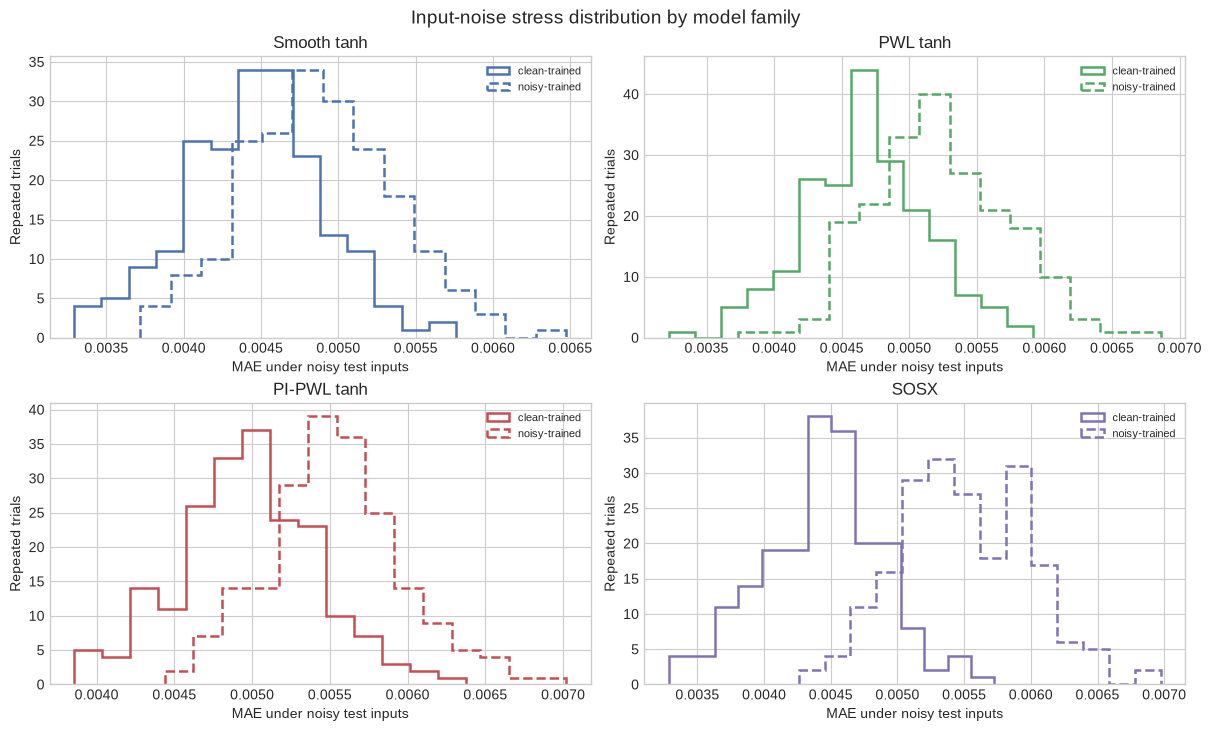

In [10]:
stress_rng = np.random.default_rng(NOISE_SEED + 1)
stress_rows = []
for repeat in range(NOISY_TEST_REPEATS):
    test_noise = stress_rng.normal(0.0, noise_std, size=X_test.shape)
    X_test_noisy = np.clip(X_test + test_noise, input_lower, input_upper)
    for label, predict in predictors.items():
        score = regression_metrics(y_test, predict(X_test_noisy))
        stress_rows.append({"repeat": repeat, "model": label, **score})

stress_metrics = pd.DataFrame(stress_rows)
stress_summary = (
    stress_metrics.groupby("model")
    .agg(
        mean_MAE=("MAE", "mean"),
        std_MAE=("MAE", "std"),
        p95_MAE=("MAE", lambda values: np.quantile(values, 0.95)),
        mean_RMSE=("RMSE", "mean"),
        mean_R2=("R2", "mean"),
    )
)
display(stress_summary)

fig, axes = plt.subplots(2, 2, figsize=(12, 7.2), constrained_layout=True)
for ax, (family, (clean_label, noisy_label)) in zip(axes.ravel(), MODEL_FAMILIES.items()):
    for label, linestyle in [(clean_label, "solid"), (noisy_label, "dashed")]:
        values = stress_metrics.loc[stress_metrics["model"] == label, "MAE"]
        ax.hist(
            values,
            bins=14,
            histtype="step",
            linewidth=1.8,
            linestyle=linestyle,
            label="clean-trained" if label == clean_label else "noisy-trained",
            color=family_colors[family],
        )
    ax.set_title(family)
    ax.set_xlabel("MAE under noisy test inputs")
    ax.set_ylabel("Repeated trials")
    ax.legend(frameon=False, fontsize=8)
fig.suptitle("Input-noise stress distribution by model family", fontsize=14)
plt.show()


## 7 · Noise-level sweep and pruning sensitivity

The previous section uses the configured training-noise level. This section tests
several independent test-input noise levels for every model view, then checks a
small pruned PWL-tanh variant. The labels remain the clean simulator outputs, so
these metrics measure sensitivity to measurement error rather than a changed
plant.

MAE                RMSE            \
                                      mean       std      mean       std   
noise fraction model                                                       
0.00           Clean-input SOSX   0.001968  0.000000  0.003294  0.000000   
               Noisy PI-PWL tanh  0.003910  0.000000  0.005973  0.000000   
               Noisy PWL tanh     0.003482  0.000000  0.005853  0.000000   
               Noisy smooth tanh  0.002690  0.000000  0.004545  0.000000   
               Noisy-input SOSX   0.003942  0.000000  0.006417  0.000000   
               PI-PWL tanh        0.002907  0.000000  0.004522  0.000000   
               PWL tanh           0.002623  0.000000  0.004384  0.000000   
               Smooth tanh        0.001677  0.000000  0.002802  0.000000   
0.01           Clean-input SOSX   0.002153  0.000104  0.003485  0.000171   
               Noisy PI-PWL tanh  0.003963  0.000103  0.006059  0.000134   
               Noisy PWL tanh     0.003590  0.000102  0.005948  0.000147   
               Noisy smooth tanh  0.002856  0.000106  0.004701  0.000130   
               Noisy-input SOSX   0.004002  0.000115  0.006500  0.000129   
               PI-PWL tanh        0.003021  0.000103  0.004648  0.000148   
               PWL tanh           0.002737  0.000106  0.004515  0.000160   
               Smooth tanh        0.001916  0.000094  0.003059  0.000149   
0.03           Clean-input SOSX   0.003102  0.000320  0.004752  0.000540   
               Noisy PI-PWL tanh  0.004501  0.000276  0.006780  0.000454   
               Noisy PWL tanh     0.004185  0.000343  0.006661  0.000573   
               Noisy smooth tanh  0.003605  0.000395  0.005643  0.000609   
               Noisy-input SOSX   0.004504  0.000347  0.007135  0.000557   
               PI-PWL tanh        0.003768  0.000259  0.005667  0.000435   
               PWL tanh           0.003537  0.000289  0.005525  0.000576   
               Smooth tanh        0.003042  0.000347  0.004575  0.000574   
0.05           Clean-input SOSX   0.004399  0.000435  0.006741  0.000631   
               Noisy PI-PWL tanh  0.005571  0.000428  0.008307  0.000595   
               Noisy PWL tanh     0.005290  0.000460  0.008188  0.000620   
               Noisy smooth tanh  0.004982  0.000437  0.007616  0.000664   
               Noisy-input SOSX   0.005613  0.000416  0.008610  0.000614   
               PI-PWL tanh        0.004955  0.000455  0.007405  0.000667   
               PWL tanh           0.004645  0.000439  0.007208  0.000619   
               Smooth tanh        0.004442  0.000503  0.006758  0.000725   

                                        R2            
                                      mean       std  
noise fraction model                                  
0.00           Clean-input SOSX   0.993628  0.000000  
               Noisy PI-PWL tanh  0.979053  0.000000  
               Noisy PWL tanh     0.979884  0.000000  
               Noisy smooth tanh  0.987869  0.000000  
               Noisy-input SOSX   0.975824  0.000000  
               PI-PWL tanh        0.987996  0.000000  
               PWL tanh           0.988713  0.000000  
               Smooth tanh        0.995392  0.000000  
0.01           Clean-input SOSX   0.992851  0.000709  
               Noisy PI-PWL tanh  0.978437  0.000960  
               Noisy PWL tanh     0.979218  0.001028  
               Noisy smooth tanh  0.987013  0.000721  
               Noisy-input SOSX   0.975186  0.000982  
               PI-PWL tanh        0.987301  0.000804  
               PWL tanh           0.988015  0.000860  
               Smooth tanh        0.994494  0.000539  
0.03           Clean-input SOSX   0.986572  0.003133  
               Noisy PI-PWL tanh  0.972889  0.003698  
               Noisy PWL tanh     0.973761  0.004705  
               Noisy smooth tanh  0.981091  0.004190  
               Noisy-input SOSX   0.969930  0.004841  
               PI-PWL tanh        0.981034  0.002937  
   

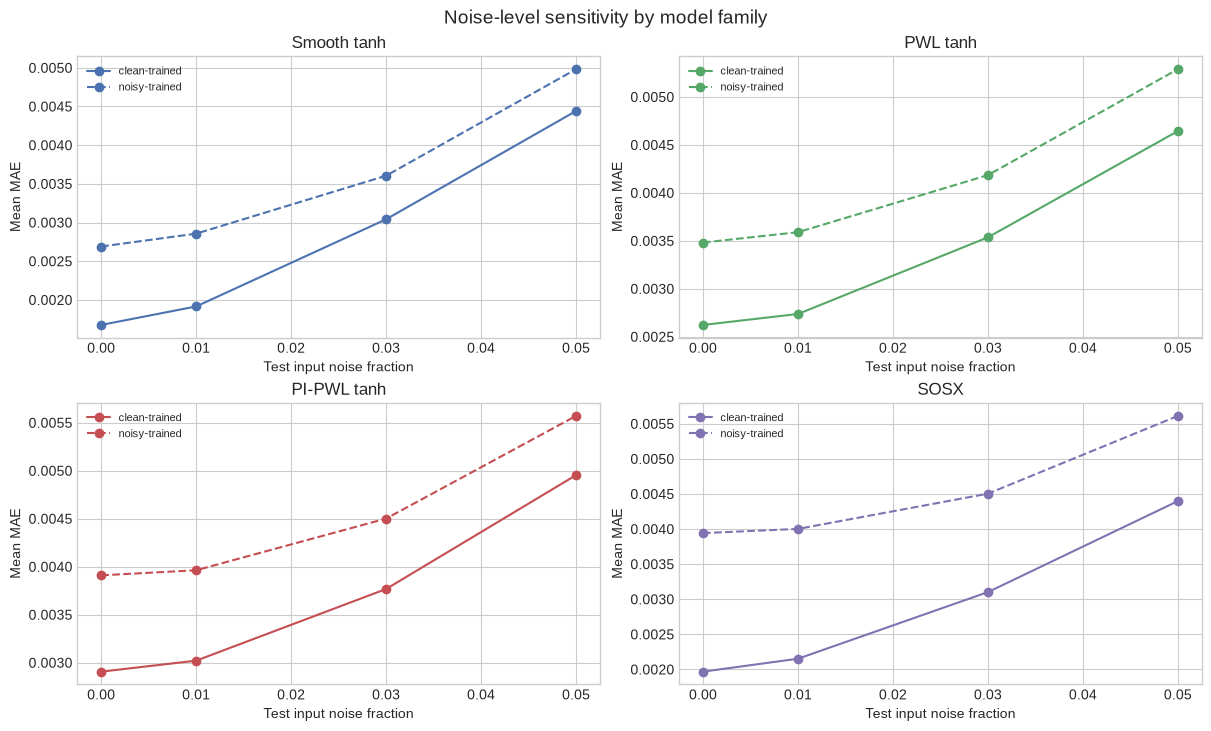

In [11]:
sweep_rng = np.random.default_rng(NOISE_SEED + 11)
noise_sweep_rows = []
for frac in NOISE_FRACTION_SWEEP:
    std = frac * input_range
    for repeat in range(max(10, NOISY_TEST_REPEATS // 5)):
        test_noise = sweep_rng.normal(0.0, std, size=X_test.shape)
        X_test_noisy_level = np.clip(X_test + test_noise, input_lower, input_upper)
        for label, predict in predictors.items():
            score = regression_metrics(y_test, predict(X_test_noisy_level))
            noise_sweep_rows.append({"noise fraction": frac, "repeat": repeat, "model": label, **score})

noise_sweep = pd.DataFrame(noise_sweep_rows)
noise_sweep_summary = (
    noise_sweep.groupby(["noise fraction", "model"])[["MAE", "RMSE", "R2"]]
    .agg(["mean", "std"])
)
display(noise_sweep_summary)

fig, axes = plt.subplots(2, 2, figsize=(12, 7.2), constrained_layout=True)
for ax, (family, (clean_label, noisy_label)) in zip(axes.ravel(), MODEL_FAMILIES.items()):
    for label, linestyle in [(clean_label, "solid"), (noisy_label, "dashed")]:
        group = noise_sweep[noise_sweep["model"] == label]
        mean_by_noise = group.groupby("noise fraction")["MAE"].mean()
        ax.plot(
            mean_by_noise.index,
            mean_by_noise.values,
            marker="o",
            linestyle=linestyle,
            label="clean-trained" if label == clean_label else "noisy-trained",
            color=family_colors[family],
        )
    ax.set_title(family)
    ax.set_xlabel("Test input noise fraction")
    ax.set_ylabel("Mean MAE")
    ax.legend(frameon=False, fontsize=8)
fig.suptitle("Noise-level sensitivity by model family", fontsize=14)
plt.show()


In [12]:
pruned_model = PWLNet(smooth_model.network).prune("neuron", fraction=0.25, X=X_train)
pin_operating_bounds(pruned_model)

def predict_pruned(X):
    return predict_pwl(pruned_model, X)

pruning_rows = []
for label, predict in [("PWL tanh", predictors["PWL tanh"]), ("PWL tanh pruned", predict_pruned)]:
    pruning_rows.append({"model": label, "split": "clean test", "hidden neurons": PWLNet(smooth_model.network).summary().n_neurons if label == "PWL tanh" else pruned_model.summary().n_neurons, **regression_metrics(y_test, predict(X_test))})
    for frac in [0.01, NOISE_FRACTION]:
        rng_local = np.random.default_rng(NOISE_SEED + int(frac * 10000))
        test_noise = rng_local.normal(0.0, frac * input_range, size=X_test.shape)
        X_noisy = np.clip(X_test + test_noise, input_lower, input_upper)
        pruning_rows.append({"model": label, "split": f"noisy test {100 * frac:.1f}%", "hidden neurons": PWLNet(smooth_model.network).summary().n_neurons if label == "PWL tanh" else pruned_model.summary().n_neurons, **regression_metrics(y_test, predict(X_noisy))})

pruning_sensitivity = pd.DataFrame(pruning_rows)
display(pruning_sensitivity)


,model,split,hidden neurons,MAE,MSE,RMSE,R2,n_samples
0,PWL tanh,clean test,6,0.002623,0.000019,0.004384,0.988713,24
1,PWL tanh,noisy test 1.0%,6,0.002712,0.000019,0.004396,0.988652,24
2,PWL tanh,noisy test 5.0%,6,0.005106,0.000053,0.007304,0.968674,24
3,PWL tanh pruned,clean test,4,0.010640,0.000189,0.013751,0.888970,24
4,PWL tanh pruned,noisy test 1.0%,4,0.010483,0.000184,0.013550,0.892196,24
5,PWL tanh pruned,noisy test 5.0%,4,0.011214,0.000211,0.014543,0.875821,24


## 8 · CPU training benchmark

,model,training wall time [s],status,nodes,scaled training MAE,scaled validation MAE,relative gap
0,Smooth tanh,31.850130,ok,NaN,NaN,NaN,NaN
1,PWL tanh,31.850130,shares smooth weights,NaN,NaN,NaN,NaN
2,Noisy smooth tanh,31.984845,ok,NaN,NaN,NaN,NaN
3,Noisy PWL tanh,31.984845,shares noisy smooth weights,NaN,NaN,NaN,NaN
4,PI-PWL tanh,5.854766,ok,NaN,NaN,NaN,NaN
5,Noisy PI-PWL tanh,5.711455,ok,NaN,NaN,NaN,NaN
6,Clean-input SOSX,30.644090,optimal,2.0,0.069839,0.070293,0.0
7,Noisy-input SOSX,28.989312,optimal,2.0,0.167179,0.110323,0.0


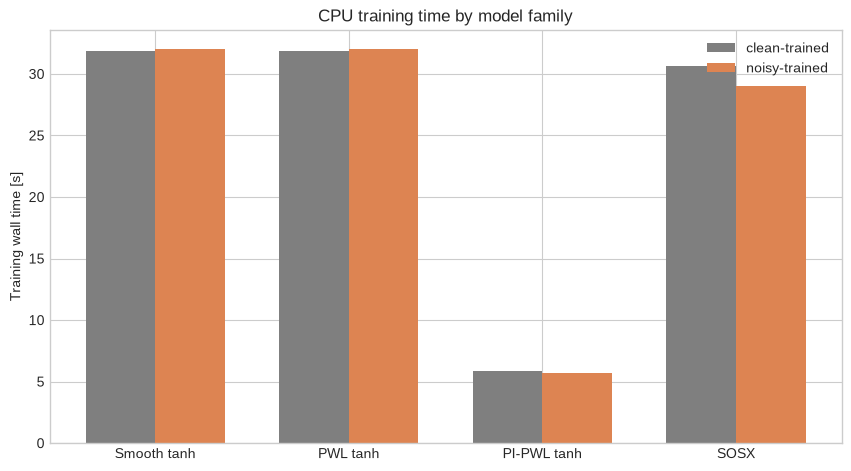

In [13]:
training_benchmark = pd.DataFrame(
    [
        {
            "model": "Smooth tanh",
            "training wall time [s]": smooth_training_seconds,
            "status": "ok",
            "nodes": np.nan,
            "scaled training MAE": np.nan,
            "scaled validation MAE": np.nan,
            "relative gap": np.nan,
        },
        {
            "model": "PWL tanh",
            "training wall time [s]": smooth_training_seconds,
            "status": "shares smooth weights",
            "nodes": np.nan,
            "scaled training MAE": np.nan,
            "scaled validation MAE": np.nan,
            "relative gap": np.nan,
        },
        {
            "model": "Noisy smooth tanh",
            "training wall time [s]": noisy_smooth_training_seconds,
            "status": "ok",
            "nodes": np.nan,
            "scaled training MAE": np.nan,
            "scaled validation MAE": np.nan,
            "relative gap": np.nan,
        },
        {
            "model": "Noisy PWL tanh",
            "training wall time [s]": noisy_smooth_training_seconds,
            "status": "shares noisy smooth weights",
            "nodes": np.nan,
            "scaled training MAE": np.nan,
            "scaled validation MAE": np.nan,
            "relative gap": np.nan,
        },
        {
            "model": "PI-PWL tanh",
            "training wall time [s]": pi_training_seconds,
            "status": "ok",
            "nodes": np.nan,
            "scaled training MAE": np.nan,
            "scaled validation MAE": np.nan,
            "relative gap": np.nan,
        },
        {
            "model": "Noisy PI-PWL tanh",
            "training wall time [s]": noisy_pi_training_seconds,
            "status": "ok",
            "nodes": np.nan,
            "scaled training MAE": np.nan,
            "scaled validation MAE": np.nan,
            "relative gap": np.nan,
        },
        {
            "model": "Clean-input SOSX",
            "training wall time [s]": clean_training_seconds,
            "status": clean_model.trainer.result_.status,
            "nodes": clean_model.trainer.n_nodes_,
            "scaled training MAE": clean_model.trainer.training_mae_,
            "scaled validation MAE": clean_model.trainer.validation_mae_,
            "relative gap": clean_model.trainer.optimality_gap_,
        },
        {
            "model": "Noisy-input SOSX",
            "training wall time [s]": noisy_training_seconds,
            "status": noisy_model.trainer.result_.status,
            "nodes": noisy_model.trainer.n_nodes_,
            "scaled training MAE": noisy_model.trainer.training_mae_,
            "scaled validation MAE": noisy_model.trainer.validation_mae_,
            "relative gap": noisy_model.trainer.optimality_gap_,
        },
    ]
)
display(training_benchmark)

training_plot_rows = []
for family, (clean_label, noisy_label) in MODEL_FAMILIES.items():
    for condition, label in [("clean-trained", clean_label), ("noisy-trained", noisy_label)]:
        value = float(training_benchmark.loc[training_benchmark["model"] == label, "training wall time [s]"].iloc[0])
        training_plot_rows.append({"family": family, "condition": condition, "training wall time [s]": value})
training_plot = pd.DataFrame(training_plot_rows)

fig, ax = plt.subplots(figsize=(8.4, 4.6), constrained_layout=True)
x = np.arange(len(MODEL_FAMILIES))
width = 0.36
clean_vals = training_plot[training_plot["condition"] == "clean-trained"]["training wall time [s]"].to_numpy()
noisy_vals = training_plot[training_plot["condition"] == "noisy-trained"]["training wall time [s]"].to_numpy()
ax.bar(x - width / 2, clean_vals, width, label="clean-trained", color="#7f7f7f")
ax.bar(x + width / 2, noisy_vals, width, label="noisy-trained", color="#dd8452")
ax.set_xticks(x)
ax.set_xticklabels(list(MODEL_FAMILIES))
ax.set_ylabel("Training wall time [s]")
ax.set_title("CPU training time by model family")
ax.legend(frameon=False)
plt.show()


## 9 · Williams–Otto solve benchmark with baseline formulations

Every model view is optimized through its natural deployment path and then
re-evaluated with the exact Williams-Otto simulator:

- smooth tanh uses exact smooth tanh NLP with Ipopt when available;
- PWL tanh and PI-PWL tanh use the big-M PWL-tanh MILP;
- clean/noisy SOSX use SOSX branch-and-LP with piecewise McCormick economics.

The table reports predicted feasibility, exact feasibility, exact-process profit,
relaxation gaps, node counts, and end-to-end wall time.


In [14]:
ipopt_path = find_ipopt()


def solve_pipeline(label, *, constrained=True):
    include = bool(constrained)
    start = time.perf_counter()
    if label == "Smooth tanh":
        if ipopt_path is None:
            return None, time.perf_counter() - start
        result = solve_surrogate_optimization_model(
            smooth_model.network,
            formulation="tanh_exact",
            solver="ipopt",
            executable=ipopt_path,
            params=params,
            include_operating_constraints=include,
            profit_formulation="bilinear",
        )
    elif label == "PWL tanh":
        result = solve_surrogate_optimization_model(
            smooth_model.network,
            formulation="tanh_pwl_bigm",
            solver=SOLVER,
            params=params,
            include_operating_constraints=include,
            profit_formulation="piecewise_mccormick",
            breakpoints=PWL_BREAKPOINTS,
            fb_segments=PWL_FB_SEGMENTS,
        )
    elif label == "Noisy smooth tanh":
        if ipopt_path is None:
            return None, time.perf_counter() - start
        result = solve_surrogate_optimization_model(
            noisy_smooth_model.network,
            formulation="tanh_exact",
            solver="ipopt",
            executable=ipopt_path,
            params=params,
            include_operating_constraints=include,
            profit_formulation="bilinear",
        )
    elif label == "Noisy PWL tanh":
        result = solve_surrogate_optimization_model(
            noisy_smooth_model.network,
            formulation="tanh_pwl_bigm",
            solver=SOLVER,
            params=params,
            include_operating_constraints=include,
            profit_formulation="piecewise_mccormick",
            breakpoints=PWL_BREAKPOINTS,
            fb_segments=PWL_FB_SEGMENTS,
        )
    elif label == "PI-PWL tanh":
        result = solve_surrogate_optimization_model(
            pi_model.network,
            formulation="tanh_pwl_bigm",
            solver=SOLVER,
            params=params,
            include_operating_constraints=include,
            profit_formulation="piecewise_mccormick",
            breakpoints=PWL_BREAKPOINTS,
            fb_segments=PWL_FB_SEGMENTS,
        )
    elif label == "Noisy PI-PWL tanh":
        result = solve_surrogate_optimization_model(
            noisy_pi_model.network,
            formulation="tanh_pwl_bigm",
            solver=SOLVER,
            params=params,
            include_operating_constraints=include,
            profit_formulation="piecewise_mccormick",
            breakpoints=PWL_BREAKPOINTS,
            fb_segments=PWL_FB_SEGMENTS,
        )
    elif label in {"Clean-input SOSX", "Noisy-input SOSX"}:
        model = models[label]
        result = solve_sosx(
            model.network,
            solver=SOLVER,
            solver_options={"persistent": True},
            params=params,
            include_operating_constraints=include,
            profit_formulation="piecewise_mccormick",
            breakpoints=PWL_BREAKPOINTS,
            max_nodes=SOSX_MAX_NODES,
            time_limit=SOSX_TIME_LIMIT,
            relative_gap=SOSX_RELATIVE_GAP,
            parallel=SOSX_PARALLEL,
            n_workers=SOSX_WORKERS,
        )
    else:
        raise KeyError(label)
    return result, time.perf_counter() - start


def solve_row(label, result, wall_seconds, case="constrained"):
    if result is None:
        return {"model": label, "case": case, "status": "skipped: Ipopt unavailable"}
    return {
        "model": label,
        "case": case,
        "status": result.status,
        "FB": result.fb,
        "TR": result.tr,
        "relaxed objective": getattr(result, "objective_value", np.nan),
        "surrogate profit": result.surrogate_profit,
        "true profit": result.exact_profit,
        "profit gap vs exact": EXACT_OPTIMUM["profit"] - result.exact_profit,
        "predicted XA": result.predicted_outputs["XA"],
        "predicted XG": result.predicted_outputs["XG"],
        "predicted feasible": (
            result.predicted_outputs["XA"] <= params.xa_max
            and result.predicted_outputs["XG"] <= params.xg_max
        ),
        "true XA": result.exact_outputs["XA"],
        "true XG": result.exact_outputs["XG"],
        "true feasible": result.exact_feasible,
        "best bound": getattr(result, "best_bound", np.nan),
        "absolute gap": getattr(result, "absolute_gap", np.nan),
        "relative gap": getattr(result, "relative_gap", np.nan),
        "nodes": getattr(result, "n_nodes", np.nan),
        "solver time [s]": getattr(result, "solve_seconds", getattr(result, "solver_seconds", np.nan)),
        "end-to-end solve [s]": wall_seconds,
    }

solve_results = {}
solve_rows = []
for label in models:
    result, wall = solve_pipeline(label, constrained=True)
    solve_results[(label, "constrained")] = result
    solve_rows.append(solve_row(label, result, wall, case="constrained"))

solve_benchmark = pd.DataFrame(solve_rows)
display(solve_benchmark)


,model,case,status,FB,TR,relaxed objective,surrogate profit,true profit,profit gap vs exact,predicted XA,...,predicted feasible,true XA,true XG,true feasible,best bound,absolute gap,relative gap,nodes,solver time [s],end-to-end solve [s]
0,Smooth tanh,constrained,ok,4.372187,80.391365,77.123610,77.123610,75.897667,-0.077667,0.120000,...,False,0.120700,0.080032,False,NaN,NaN,NaN,NaN,0.014998,0.076841
1,PWL tanh,constrained,ok,4.532288,80.611802,72.908781,70.531511,71.871753,3.948247,0.114007,...,True,0.116488,0.076628,True,NaN,NaN,NaN,NaN,0.211426,0.215489
2,Noisy smooth tanh,constrained,ok,4.315511,80.736708,74.054010,74.054010,78.644764,-2.824764,0.120000,...,False,0.121026,0.083147,False,NaN,NaN,NaN,NaN,0.016082,0.019867
3,Noisy PWL tanh,constrained,ok,4.513657,81.020549,66.876744,63.989445,74.190770,1.629230,0.114208,...,True,0.115716,0.078828,True,NaN,NaN,NaN,NaN,0.172928,0.176726
4,PI-PWL tanh,constrained,ok,4.511574,79.773808,51.326643,49.153782,68.738018,7.081982,0.116269,...,True,0.119356,0.073714,True,NaN,NaN,NaN,NaN,0.139555,0.143601
5,Noisy PI-PWL tanh,constrained,ok,4.478742,79.323078,46.192615,44.290080,67.699545,8.120455,0.116519,...,True,0.121396,0.072703,False,NaN,NaN,NaN,NaN,0.102351,0.107930
6,Clean-input SOSX,constrained,gap_limit,4.516235,80.608723,71.001349,67.801766,72.394693,3.425307,0.115526,...,True,0.116842,0.077040,True,69.169964,0.0,0.0,33.0,1.271694,1.283101
7,Noisy-input SOSX,constrained,gap_limit,4.205408,79.606948,71.719749,68.401441,77.172027,-1.352027,0.119281,...,True,0.127096,0.081313,False,70.796176,0.0,0.0,29.0,0.980468,0.990943


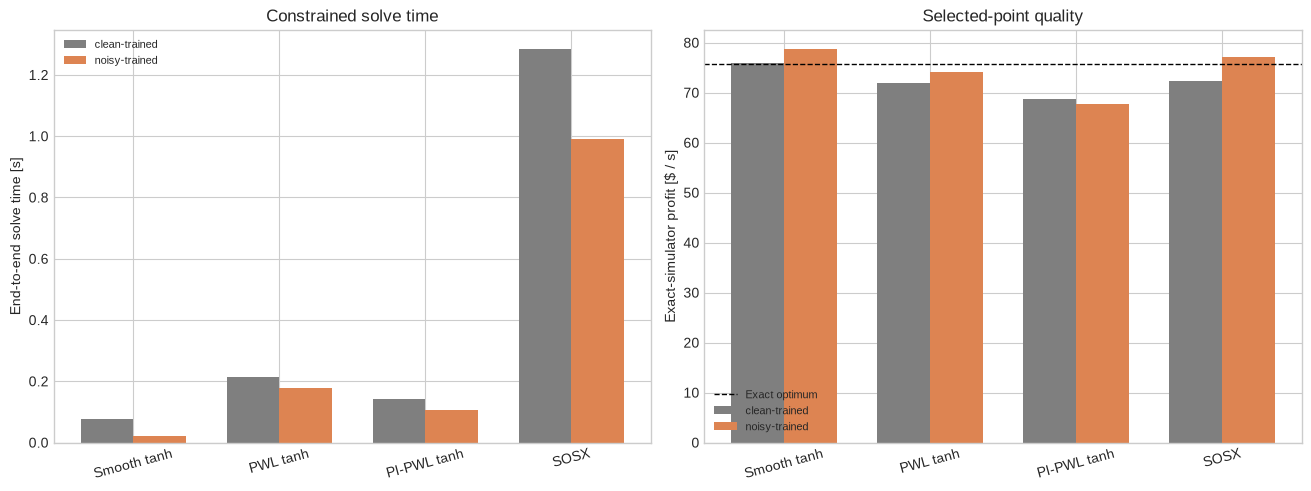

In [15]:
solve_plot_rows = []
for family, (clean_label, noisy_label) in MODEL_FAMILIES.items():
    for condition, label in [("clean-trained", clean_label), ("noisy-trained", noisy_label)]:
        row = solve_benchmark.loc[solve_benchmark["model"] == label].iloc[0]
        solve_plot_rows.append(
            {
                "family": family,
                "condition": condition,
                "true profit": row["true profit"],
                "end-to-end solve [s]": row["end-to-end solve [s]"],
                "true feasible": row["true feasible"],
            }
        )
solve_plot = pd.DataFrame(solve_plot_rows)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
x = np.arange(len(MODEL_FAMILIES))
width = 0.36
for ax, column, ylabel, title in [
    (axes[0], "end-to-end solve [s]", "End-to-end solve time [s]", "Constrained solve time"),
    (axes[1], "true profit", "Exact-simulator profit [$ / s]", "Selected-point quality"),
]:
    clean_vals = solve_plot[solve_plot["condition"] == "clean-trained"][column].to_numpy(dtype=float)
    noisy_vals = solve_plot[solve_plot["condition"] == "noisy-trained"][column].to_numpy(dtype=float)
    ax.bar(x - width / 2, clean_vals, width, label="clean-trained", color="#7f7f7f")
    ax.bar(x + width / 2, noisy_vals, width, label="noisy-trained", color="#dd8452")
    ax.set_xticks(x)
    ax.set_xticklabels(list(MODEL_FAMILIES), rotation=15)
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if column == "true profit":
        ax.axhline(EXACT_OPTIMUM["profit"], color="black", linestyle="--", linewidth=1, label="Exact optimum")
    ax.legend(frameon=False, fontsize=8)
plt.show()


## 10 · Constrained versus unconstrained optimization

The constrained solve can look good while the unconstrained surrogate optimum is
unsafe. This section solves each model view with and without the `XA`/`XG`
operating constraints and reports exact-process feasibility in both cases.

In [16]:
constraint_rows = []
for label in models:
    for case, constrained in [("unconstrained", False), ("constrained", True)]:
        if (label, case) in solve_results:
            result = solve_results[(label, case)]
            wall = np.nan
        else:
            result, wall = solve_pipeline(label, constrained=constrained)
            solve_results[(label, case)] = result
        constraint_rows.append(solve_row(label, result, wall, case=case))

constraint_benchmark = pd.DataFrame(constraint_rows)
display(constraint_benchmark)


,model,case,status,FB,TR,relaxed objective,surrogate profit,true profit,profit gap vs exact,predicted XA,...,predicted feasible,true XA,true XG,true feasible,best bound,absolute gap,relative gap,nodes,solver time [s],end-to-end solve [s]
0,Smooth tanh,unconstrained,ok,4.000000,85.288334,93.501075,93.501075,88.055215,-12.235215,0.111819,...,False,0.115915,0.115516,False,NaN,NaN,NaN,NaN,0.013739,0.018823
1,Smooth tanh,constrained,ok,4.372187,80.391365,77.123610,77.123610,75.897667,-0.077667,0.120000,...,False,0.120700,0.080032,False,NaN,NaN,NaN,NaN,0.014998,NaN
2,PWL tanh,unconstrained,ok,4.000000,87.655349,91.908638,91.908638,85.826008,-10.006008,0.104749,...,False,0.109299,0.127680,False,NaN,NaN,NaN,NaN,0.203160,0.207801
3,PWL tanh,constrained,ok,4.532288,80.611802,72.908781,70.531511,71.871753,3.948247,0.114007,...,True,0.116488,0.076628,True,NaN,NaN,NaN,NaN,0.211426,NaN
4,Noisy smooth tanh,unconstrained,ok,4.000000,87.151510,93.698584,93.698584,86.524747,-10.704747,0.106620,...,False,0.110689,0.125075,False,NaN,NaN,NaN,NaN,0.014648,0.018277
5,Noisy smooth tanh,constrained,ok,4.315511,80.736708,74.054010,74.054010,78.644764,-2.824764,0.120000,...,False,0.121026,0.083147,False,NaN,NaN,NaN,NaN,0.016082,NaN
6,Noisy PWL tanh,unconstrained,ok,4.000000,89.551433,92.826471,92.826471,82.192676,-6.372676,0.100600,...,False,0.104166,0.137531,False,NaN,NaN,NaN,NaN,0.166021,0.171683
7,Noisy PWL tanh,constrained,ok,4.513657,81.020549,66.876744,63.989445,74.190770,1.629230,0.114208,...,True,0.115716,0.078828,True,NaN,NaN,NaN,NaN,0.172928,NaN
8,PI-PWL tanh,unconstrained,ok,4.000000,100.000000,93.034969,93.034969,40.452147,35.367853,0.081523,...,False,0.078677,0.191535,False,NaN,NaN,NaN,NaN,0.133331,0.137197
9,PI-PWL tanh,constrained,ok,4.511574,79.773808,51.326643,49.153782,68.738018,7.081982,0.116269,...,True,0.119356,0.073714,True,NaN,NaN,NaN,NaN,0.139555,NaN


## 11 · Exact profit and feasibility landscape

The background is the exact Williams–Otto simulator profit. Shaded regions violate
the exact-process constraints `XA <= 0.12` or `XG <= 0.08`; the corresponding
constraint boundaries are drawn as contour lines. Each SOSX-selected point is
marked and annotated with both surrogate-predicted and exact-process feasibility.

A point can be feasible for the embedded surrogate but infeasible for the exact
process because of surrogate and PWL approximation error.

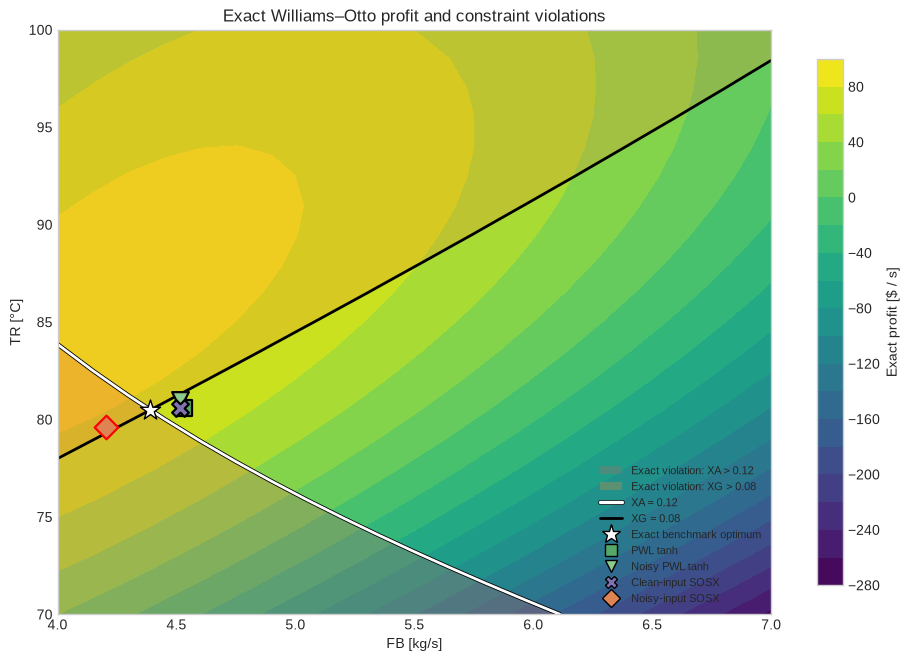

,model,FB,TR,predicted XA,predicted XG,predicted feasible,true XA,true XG,true feasible,true profit
0,Smooth tanh,4.372187,80.391365,0.120000,0.08,False,0.120700,0.080032,False,75.897667
1,PWL tanh,4.532288,80.611802,0.114007,0.08,True,0.116488,0.076628,True,71.871753
2,Noisy smooth tanh,4.315511,80.736708,0.120000,0.08,False,0.121026,0.083147,False,78.644764
3,Noisy PWL tanh,4.513657,81.020549,0.114208,0.08,True,0.115716,0.078828,True,74.190770
4,PI-PWL tanh,4.511574,79.773808,0.116269,0.08,True,0.119356,0.073714,True,68.738018
5,Noisy PI-PWL tanh,4.478742,79.323078,0.116519,0.08,True,0.121396,0.072703,False,67.699545
6,Clean-input SOSX,4.516235,80.608723,0.115526,0.08,True,0.116842,0.077040,True,72.394693
7,Noisy-input SOSX,4.205408,79.606948,0.119281,0.08,True,0.127096,0.081313,False,77.172027


In [17]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.patheffects as pe

landscape = generate_dataset(
    n_samples=441,
    method="grid",
    random_state=RANDOM_SEED,
    as_frame=True,
)


def grid_values(frame, column):
    table = frame.pivot(index="TR", columns="FB", values=column).sort_index()
    return (
        table.columns.to_numpy(dtype=float),
        table.index.to_numpy(dtype=float),
        table.to_numpy(dtype=float),
    )


fb_grid, tr_grid, profit_grid = grid_values(landscape, "profit")
_, _, xa_grid = grid_values(landscape, "XA")
_, _, xg_grid = grid_values(landscape, "XG")

fig, ax = plt.subplots(figsize=(9, 6.5), constrained_layout=True)
profit_contour = ax.contourf(
    fb_grid, tr_grid, profit_grid, levels=18, cmap="viridis"
)

xa_upper = float(np.nanmax(xa_grid))
xg_upper = float(np.nanmax(xg_grid))
if xa_upper > params.xa_max:
    ax.contourf(
        fb_grid,
        tr_grid,
        xa_grid,
        levels=[params.xa_max, xa_upper],
        colors=["#E15759"],
        alpha=0.24,
    )
if xg_upper > params.xg_max:
    ax.contourf(
        fb_grid,
        tr_grid,
        xg_grid,
        levels=[params.xg_max, xg_upper],
        colors=["#F28E2B"],
        alpha=0.28,
    )

xa_line = ax.contour(
    fb_grid,
    tr_grid,
    xa_grid,
    levels=[params.xa_max],
    colors="white",
    linewidths=2.0,
)
xg_line = ax.contour(
    fb_grid,
    tr_grid,
    xg_grid,
    levels=[params.xg_max],
    colors="black",
    linewidths=2.0,
)
xa_line.set_path_effects(
    [pe.Stroke(linewidth=3.2, foreground="black"), pe.Normal()]
)

ax.scatter(
    [EXACT_OPTIMUM["FB"]],
    [EXACT_OPTIMUM["TR"]],
    marker="*",
    s=230,
    color="white",
    edgecolor="black",
    linewidth=1.0,
    zorder=7,
)

for _, row in solve_benchmark[solve_benchmark["model"].isin(MAIN_LANDSCAPE_MODELS)].dropna(subset=["FB", "TR"]).iterrows():
    edge = "black" if bool(row["true feasible"]) else "red"
    ax.scatter(
        [row["FB"]],
        [row["TR"]],
        marker=model_markers[row["model"]],
        s=145,
        color=model_colors[row["model"]],
        edgecolor=edge,
        linewidth=1.6,
        zorder=8,
    )

ax.set_title("Exact Williams–Otto profit and constraint violations")
ax.set_xlabel("FB [kg/s]")
ax.set_ylabel("TR [°C]")
fig.colorbar(profit_contour, ax=ax, shrink=0.9, label="Exact profit [$ / s]")

legend_handles = [
    Patch(facecolor="#E15759", alpha=0.24, label="Exact violation: XA > 0.12"),
    Patch(facecolor="#F28E2B", alpha=0.28, label="Exact violation: XG > 0.08"),
    Line2D(
        [0], [0], color="white", lw=2.4, label="XA = 0.12",
        path_effects=[pe.Stroke(linewidth=3.4, foreground="black"), pe.Normal()],
    ),
    Line2D([0], [0], color="black", lw=2.0, label="XG = 0.08"),
    Line2D(
        [0], [0], marker="*", color="white", markeredgecolor="black",
        markersize=14, linestyle="None", label="Exact benchmark optimum",
    ),
]
legend_handles.extend(
    Line2D(
        [0], [0], marker=model_markers[label], color=model_colors[label],
        markeredgecolor="black", markersize=9, linestyle="None", label=label,
    )
    for label in MAIN_LANDSCAPE_MODELS
)
ax.legend(handles=legend_handles, loc="lower right", fontsize=8, framealpha=0.95)
plt.show()

display(
    solve_benchmark[
        [
            "model", "FB", "TR", "predicted XA", "predicted XG",
            "predicted feasible", "true XA", "true XG", "true feasible",
            "true profit",
        ]
    ]
)

## 12 · Optional repeated-seed and parameter-drift evidence

This cell is disabled by default because it retrains several models and adds
extra exact-process evaluations. Enable `RUN_EXTENDED_ROBUSTNESS` in the
configuration cell when preparing release-grade robustness evidence.

In [18]:
if RUN_EXTENDED_ROBUSTNESS:
    repeated_rows = []
    for seed in REPEATED_SEEDS:
        split_i = train_val_test_split(data, val_size=0.2, test_size=0.2, random_state=seed)
        Xi_train, yi_train = split_xy(split_i.train)
        Xi_val, yi_val = split_xy(split_i.validation)
        Xi_test, yi_test = split_xy(split_i.test)
        model_i = PWLNet.train(
            Xi_train,
            yi_train,
            hidden_layers=[HIDDEN],
            activation="tanh",
            loss="mse",
            epochs=max(100, KERAS_OPTIONS["epochs"] // 4),
            batch_size=KERAS_OPTIONS["batch_size"],
            validation_data=(Xi_val, yi_val),
            early_stopping_patience=25,
            random_seed=seed,
            verbose=0,
        )
        pin_operating_bounds(model_i)
        pred_i = evaluate_tanh_pwl_network(model_i.network, Xi_test, breakpoints=PWL_BREAKPOINTS)
        repeated_rows.append({"seed": seed, "model": "PWL tanh", **regression_metrics(yi_test, pred_i)})
    repeated_seed_summary = pd.DataFrame(repeated_rows)
    display(repeated_seed_summary)
    display(repeated_seed_summary[["MAE", "RMSE", "R2"]].agg(["mean", "std"]))

    from dataclasses import replace
    from pwlnet.processes.williams_otto import solve_steady_state

    drift_rows = []
    for scale in [0.85, 1.0, 1.15]:
        drift_params = replace(params, a1=params.a1 * scale)
        for _, row in solve_benchmark.dropna(subset=["FB", "TR"]).iterrows():
            exact = solve_steady_state(row["FB"], row["TR"], params=drift_params)
            exact_outputs = dict(zip(OUTPUT_NAMES, exact.x))
            drift_rows.append(
                {
                    "k1 scale": scale,
                    "model": row["model"],
                    "FB": row["FB"],
                    "TR": row["TR"],
                    "drift true profit": exact.profit,
                    "drift true XA": exact_outputs["XA"],
                    "drift true XG": exact_outputs["XG"],
                    "drift true feasible": exact_outputs["XA"] <= drift_params.xa_max and exact_outputs["XG"] <= drift_params.xg_max,
                }
            )
    drift_benchmark = pd.DataFrame(drift_rows)
    display(drift_benchmark)
else:
    print("Extended robustness diagnostics are disabled. Set RUN_EXTENDED_ROBUSTNESS = True to run them.")


Extended robustness diagnostics are disabled. Set RUN_EXTENDED_ROBUSTNESS = True to run them.


## 13 · Interpretation

Evidence against overfitting is strongest when the noisy-input model:

- has a train-to-test gap comparable to the clean model;
- preserves clean validation and test accuracy;
- has a similar or better noisy-test MAE distribution;
- selects a feasible Williams–Otto point with comparable true profit;
- behaves consistently across several random seeds and noise levels;
- remains comparable to smooth/PWL/PI baselines under the same exact-process checks;
- does not rely on the unconstrained surrogate optimum being accidentally feasible.

Do not interpret a lower training MAE alone as robustness. The decisive quantities
are clean holdout performance, noisy-input sensitivity, and downstream exact-process
performance.

Why noisy-input training can look worse: the labels are still simulator outputs at the original clean `(FB, TR)` points, while the model sees displaced inputs. That creates an errors-in-variables target: nearby but wrong operating points are asked to produce the clean label. At `NOISE_FRACTION = 0.05`, this is a large perturbation relative to a 120-sample data set (`FB` std 0.15 kg/s and `TR` std 1.5 degC), so the fitted mapping is biased/smoothed. SOSX is especially exposed because it uses a small fixed-readout PWL-tanh architecture and optimizes a bounded MAE problem; noisy inputs can move samples across active PWL regions and constraint-sensitive parts of the surface.


## Appendix · All-model profit landscapes

The main narrative avoids overlaying all eight model views. This appendix keeps
the complete per-model profit landscape diagnostics available for audit. Set
`RUN_APPENDIX_PLOTS = True` to render every landscape; the summary error table is
shown either way.


In [19]:
landscape_X = landscape[INPUT_NAMES].to_numpy(dtype=float)
landscape_error_rows = []

for label, predict in predictors.items():
    model_landscape = landscape.copy()
    predicted_grid = predict(landscape_X)
    for j, output in enumerate(OUTPUT_NAMES):
        model_landscape[f"{output}_pred"] = predicted_grid[:, j]

    flow = params.fa + model_landscape["FB"].to_numpy(dtype=float)
    model_landscape["profit_pred"] = (
        (
            params.price_p * model_landscape["XP_pred"].to_numpy(dtype=float)
            + params.price_e * model_landscape["XE_pred"].to_numpy(dtype=float)
        )
        * flow
        - params.cost_a * params.fa
        - params.cost_b * model_landscape["FB"].to_numpy(dtype=float)
    )
    model_landscape["profit_abs_error"] = np.abs(
        model_landscape["profit_pred"] - model_landscape["profit"]
    )

    grid_mae = float(model_landscape["profit_abs_error"].mean())
    grid_max = float(model_landscape["profit_abs_error"].max())
    landscape_error_rows.append(
        {
            "model": label,
            "profit grid MAE": grid_mae,
            "profit grid RMSE": float(
                np.sqrt(np.mean(np.square(model_landscape["profit_pred"] - model_landscape["profit"])))
            ),
            "profit grid max abs error": grid_max,
        }
    )

    if RUN_APPENDIX_PLOTS:
        exact_profit = model_landscape["profit"].to_numpy(dtype=float)
        surrogate_profit = model_landscape["profit_pred"].to_numpy(dtype=float)
        profit_lo = float(min(exact_profit.min(), surrogate_profit.min()))
        profit_hi = float(max(exact_profit.max(), surrogate_profit.max()))
        profit_levels = np.linspace(profit_lo, profit_hi, 15)
        selected = solve_benchmark.loc[solve_benchmark["model"] == label].iloc[0]
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), constrained_layout=True)
        for ax, column, title, cmap in zip(
            axes,
            ["profit", "profit_pred", "profit_abs_error"],
            ["Exact profit", "Surrogate-implied profit", "Absolute profit error"],
            ["viridis", "viridis", "inferno"],
        ):
            fb_plot, tr_plot, values = grid_values(model_landscape, column)
            levels = profit_levels if column != "profit_abs_error" else 14
            contour = ax.contourf(fb_plot, tr_plot, values, levels=levels, cmap=cmap)
            ax.scatter([EXACT_OPTIMUM["FB"]], [EXACT_OPTIMUM["TR"]], marker="*", s=145, color="white", edgecolor="black", linewidth=0.8, zorder=5)
            ax.scatter([selected["FB"]], [selected["TR"]], marker=model_markers[label], s=105, color=model_colors[label], edgecolor="black" if bool(selected["true feasible"]) else "red", linewidth=1.2, zorder=6)
            ax.set_title(title)
            ax.set_xlabel("FB [kg/s]")
            ax.set_ylabel("TR [degC]")
            fig.colorbar(contour, ax=ax, shrink=0.85)
        fig.suptitle(f"{label}: profit landscapes - grid MAE={grid_mae:.2f}, max error={grid_max:.2f}", fontsize=14)
        plt.show()

display(pd.DataFrame(landscape_error_rows).sort_values("profit grid MAE"))


,model,profit grid MAE,profit grid RMSE,profit grid max abs error
0,Smooth tanh,6.244397,10.701276,70.115089
1,PWL tanh,8.253894,12.953471,81.139282
6,Clean-input SOSX,8.922075,16.887685,107.646821
2,Noisy smooth tanh,9.728210,14.049009,79.155666
3,Noisy PWL tanh,10.985562,16.300040,88.613692
7,Noisy-input SOSX,13.740464,25.006777,151.553739
4,PI-PWL tanh,17.568784,24.697875,122.713878
5,Noisy PI-PWL tanh,19.783116,27.416601,128.432758
